# PBL 1: Machine Learning Analysis Pipeline
### Demolition Waste & Construction Material Image Feature Analysis

**Pipeline Overview:**
1. **Dataset Loading & Exploration:** Ingestion of training, validation, and testing CSV files.
2. **Exploratory Data Analysis & Leakage Diagnostics:**
   - Material Category Distribution
   - Condition Class Distribution (evaluating class imbalance)
   - Recovery Pathway Distribution
   - Correlation Heatmap (strictly numerical computer vision features)
   - Deterministic range checks to prevent data leakage from derived target scores
3. **Polynomial Curve Fitting (Degree 1 to 5):**
   - Evaluating non-linear fits between texture variance and continuous damage score
   - Bias-Variance tradeoff analysis (underfitting vs. overfitting)
4. **Regression Algorithms Comparison:**
   - Linear Regression, Ridge ($L_2$), Lasso ($L_1$), Polynomial Regression (Degree 2), Decision Tree, Random Forest
   - Metrics: MAE, MSE, RMSE, and $R^2$ Score
   - Actual vs. Predicted scatter plots
5. **Classification Algorithms Comparison:**
   - Multi-class classification of `Condition_Class` (`Excellent`, `Good`, `Fair`, `Poor`)
   - Logistic Regression, Decision Tree, Random Forest, Support Vector Machine (RBF), K-Nearest Neighbors
   - Metrics: Accuracy, Weighted Precision, Recall, F1-Score, and Confusion Matrices
6. **Comparative Performance Analysis:**
   - Side-by-side benchmark bar charts
7. **Algorithm Explanations & Theory:**
   - Mathematical formulations, regularization penalties, and domain-specific engineering insights


In [2]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, PolynomialFeatures, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Visual styling setup
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 10})
%matplotlib inline


## 1. Dataset Ingestion & Validation
We load the three provided CSV feature sets (`training_image_features.csv`, `validation_image_features.csv`, and `testing_image_features.csv`).


In [3]:
# Project directory paths (loads outside CSVs from parent directory)
parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if not os.path.exists(os.path.join(parent_dir, "training_image_features.csv")):
    parent_dir = os.getcwd()  # Fallback if notebook is run in project root

train_path = os.path.join(parent_dir, "training_image_features.csv")
val_path = os.path.join(parent_dir, "validation_image_features.csv")
test_path = os.path.join(parent_dir, "testing_image_features.csv")

print("[*] Loading CSV datasets...")
print(f"    Train: {train_path}")
print(f"    Val:   {val_path}")
print(f"    Test:  {test_path}")

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print(f"[+] Loaded shapes: Train={train_df.shape}, Val={val_df.shape}, Test={test_df.shape}")

# Combined dataset for overall EDA
full_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
print(f"[+] Total records across sets: {len(full_df):,}")


[*] Loading CSV datasets...
    Train: d:\programs\LearningFundamentals\Ml_clg\project_ml\training_image_features.csv
    Val:   d:\programs\LearningFundamentals\Ml_clg\project_ml\validation_image_features.csv
    Test:  d:\programs\LearningFundamentals\Ml_clg\project_ml\testing_image_features.csv
[+] Loaded shapes: Train=(10058, 43), Val=(3237, 43), Test=(3224, 43)
[+] Total records across sets: 16,519


## 2. Feature Selection & Data Leakage Diagnostic
To ensure models evaluate real computer vision predictability and avoid **data leakage**, we select only raw visual and morphological image features, strictly excluding derived score fields (`Damage_Score`, `Condition_Score`, `Alternative_Use_Suitability`).


In [4]:
# Extracted computer vision numerical features
feature_cols = [
    'pixel_obj_width', 'pixel_obj_height', 'relative_area', 'edge_density',
    'fill_ratio', 'color_std', 'mean_brightness', 'std_brightness', 'contrast',
    'texture_laplacian_var', 'dark_pixel_ratio', 'bright_pixel_ratio', 'mean_hue',
    'mean_saturation', 'saturation_std', 'contour_area', 'contour_perimeter',
    'circularity', 'solidity', 'extent'
]

print(f"Selected {len(feature_cols)} numerical features for model training:")
print(feature_cols)

# Data leakage verification check
print("\n=== DATA LEAKAGE DIAGNOSTIC: Range Overlap Check ===")
cond_check = full_df.groupby("Condition_Class")[["Damage_Score", "Condition_Score"]].agg(['min', 'max', 'count'])
print(cond_check)

rec_check = full_df.groupby("Recovery_Pathway")[["Damage_Score", "Condition_Score"]].agg(['min', 'max', 'count'])
print(rec_check)

print('''
Finding:
There is 0% range overlap between classes. Condition_Class and Recovery_Pathway are deterministic
binnings of Damage_Score and Condition_Score. Therefore, continuous score columns MUST NOT be included
as input features when predicting Condition_Class or Recovery_Pathway.
''')


Selected 20 numerical features for model training:
['pixel_obj_width', 'pixel_obj_height', 'relative_area', 'edge_density', 'fill_ratio', 'color_std', 'mean_brightness', 'std_brightness', 'contrast', 'texture_laplacian_var', 'dark_pixel_ratio', 'bright_pixel_ratio', 'mean_hue', 'mean_saturation', 'saturation_std', 'contour_area', 'contour_perimeter', 'circularity', 'solidity', 'extent']

=== DATA LEAKAGE DIAGNOSTIC: Range Overlap Check ===
                Damage_Score             Condition_Score            
                         min  max  count             min  max  count
Condition_Class                                                     
Excellent                1.0  1.3    181             8.0  8.5    181
Fair                     2.7  4.0  11283             4.0  5.9  11283
Good                     1.7  2.3   3614             6.6  7.4   3614
Poor                     4.3  5.0   1441             2.5  3.6   1441
                                Damage_Score             Condition_Score 

## 3. Exploratory Data Analysis & Class Imbalance
We visualize the material distribution, condition class distribution (highlighting class imbalance), recovery pathway distribution, and the feature correlation heatmap.


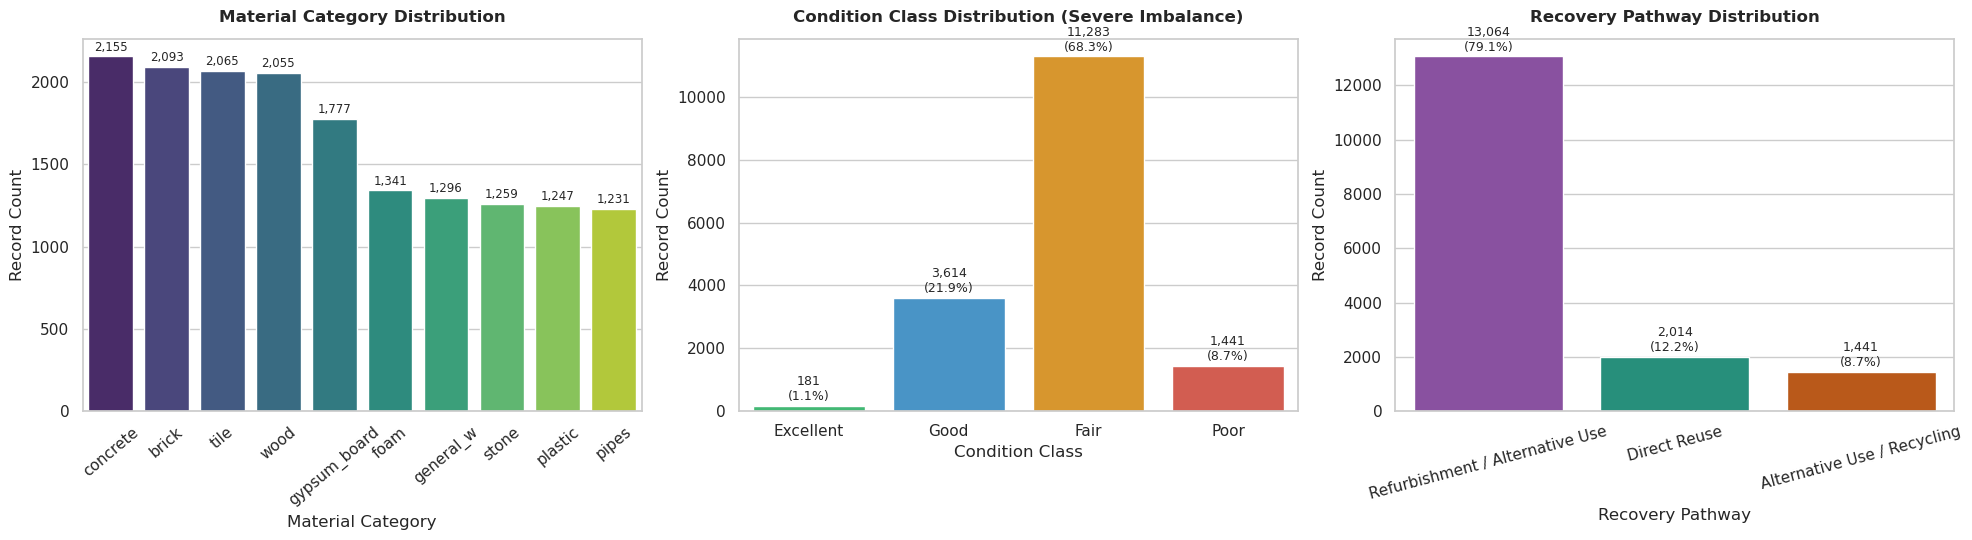

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# 1. Material Category Distribution
mat_counts = full_df["Material_Type"].value_counts()
sns.barplot(x=mat_counts.index, y=mat_counts.values, ax=axes[0], hue=mat_counts.index, palette="viridis", legend=False)
axes[0].set_title("Material Category Distribution", fontweight='bold', pad=12)
axes[0].set_xlabel("Material Category")
axes[0].set_ylabel("Record Count")
axes[0].tick_params(axis='x', rotation=40)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=8.5, xytext=(0, 2), textcoords='offset points')

# 2. Condition Class Distribution
cond_order = ["Excellent", "Good", "Fair", "Poor"]
cond_counts = full_df["Condition_Class"].value_counts().reindex(cond_order)
sns.barplot(x=cond_counts.index, y=cond_counts.values, ax=axes[1], hue=cond_counts.index,
            palette=["#2ecc71", "#3498db", "#f39c12", "#e74c3c"], legend=False)
axes[1].set_title("Condition Class Distribution (Severe Imbalance)", fontweight='bold', pad=12)
axes[1].set_xlabel("Condition Class")
axes[1].set_ylabel("Record Count")
for p in axes[1].patches:
    pct = (p.get_height() / len(full_df)) * 100
    axes[1].annotate(f"{int(p.get_height()):,}\n({pct:.1f}%)", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

# 3. Recovery Pathway Distribution
rec_counts = full_df["Recovery_Pathway"].value_counts()
sns.barplot(x=rec_counts.index, y=rec_counts.values, ax=axes[2], hue=rec_counts.index,
            palette=["#8e44ad", "#16a085", "#d35400"], legend=False)
axes[2].set_title("Recovery Pathway Distribution", fontweight='bold', pad=12)
axes[2].set_xlabel("Recovery Pathway")
axes[2].set_ylabel("Record Count")
axes[2].tick_params(axis='x', rotation=15)
for p in axes[2].patches:
    pct = (p.get_height() / len(full_df)) * 100
    axes[2].annotate(f"{int(p.get_height()):,}\n({pct:.1f}%)", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()


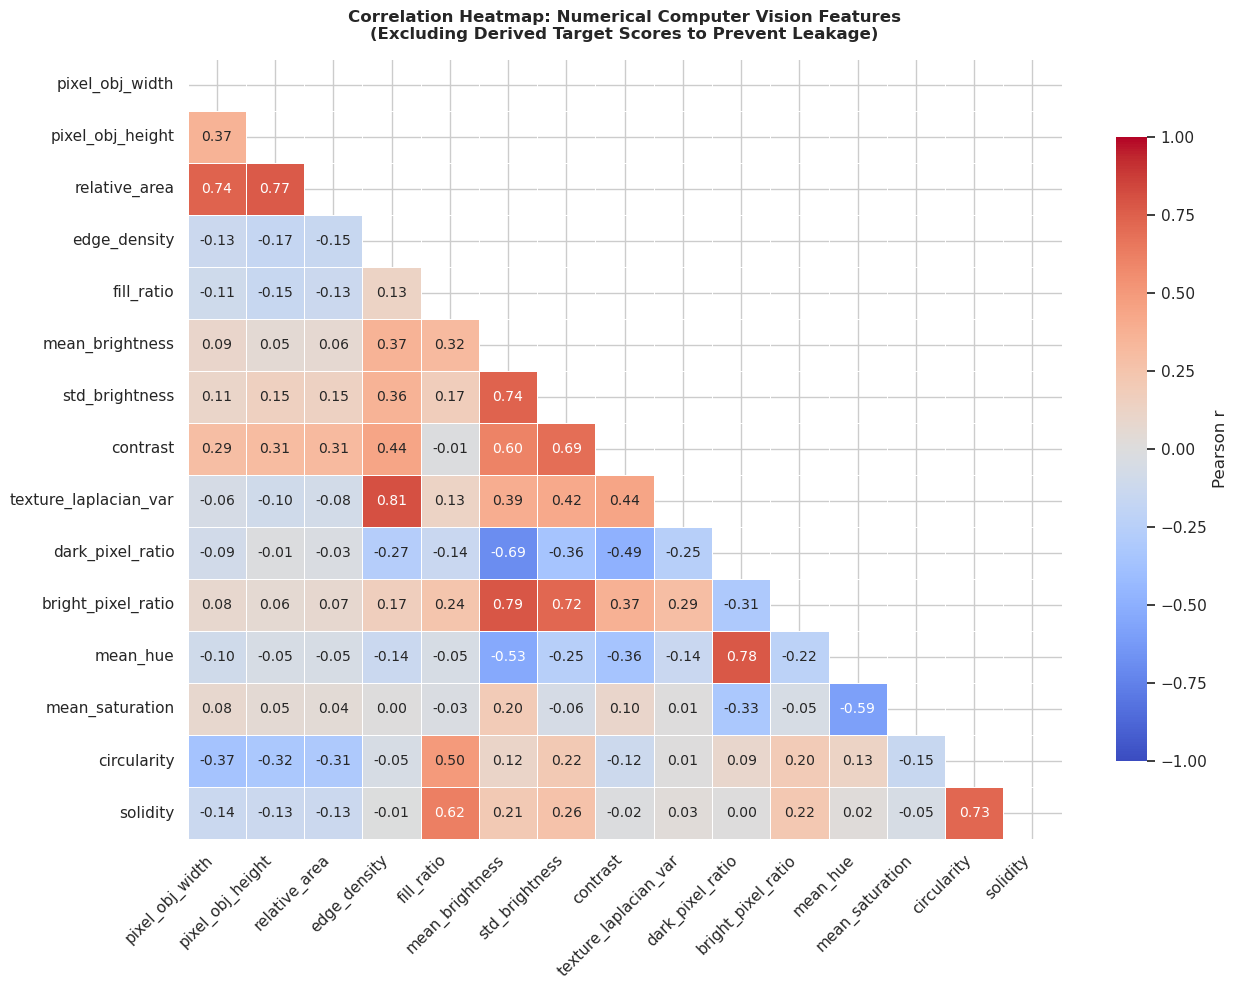

In [6]:
# 4. Correlation Heatmap (Strictly numerical CV features)
plt.figure(figsize=(13, 10))
corr_subset = [
    'pixel_obj_width', 'pixel_obj_height', 'relative_area', 'edge_density',
    'fill_ratio', 'mean_brightness', 'std_brightness', 'contrast',
    'texture_laplacian_var', 'dark_pixel_ratio', 'bright_pixel_ratio',
    'mean_hue', 'mean_saturation', 'circularity', 'solidity'
]

corr_matrix = full_df[corr_subset].corr(method='pearson')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson r"}
)
plt.title("Correlation Heatmap: Numerical Computer Vision Features\n(Excluding Derived Target Scores to Prevent Leakage)",
          fontweight='bold', pad=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 4. Polynomial Curve Fitting (Underfitting vs. Overfitting)
We fit polynomials of degree 1 through 5 mapping Laplacian texture variance to continuous `Damage_Score` to demonstrate the bias-variance tradeoff.


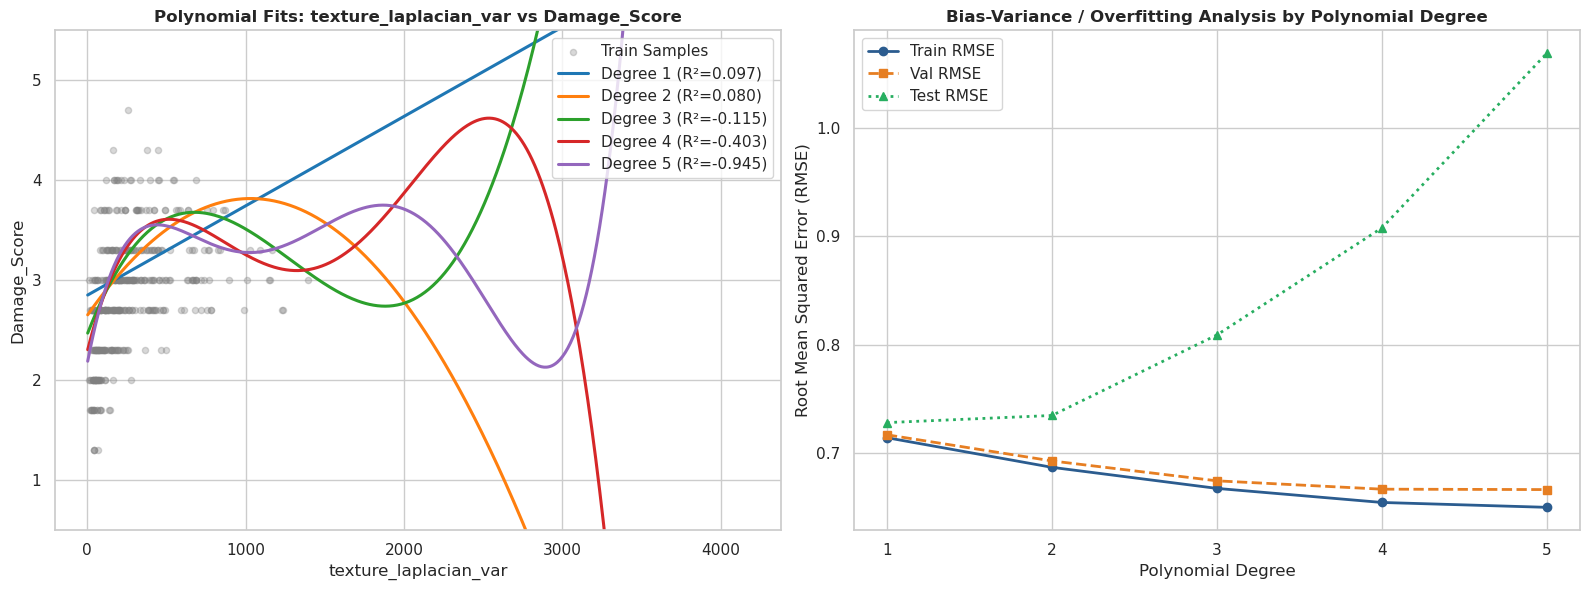

   Degree  Train_RMSE  Val_RMSE  Test_RMSE   Test_R2
0       1    0.714468  0.717141   0.728378  0.096541
1       2    0.687182  0.693076   0.734944  0.080179
2       3    0.667765  0.674733   0.809136 -0.114906
3       4    0.654811  0.667053   0.907764 -0.403269
4       5    0.650328  0.666679   1.068771 -0.945200


In [7]:
feature_col = "texture_laplacian_var"
target_col = "Damage_Score"

X_train_poly = train_df[[feature_col]].values
y_train_poly = train_df[target_col].values
X_val_poly = val_df[[feature_col]].values
y_val_poly = val_df[target_col].values
X_test_poly = test_df[[feature_col]].values
y_test_poly = test_df[target_col].values

degrees = [1, 2, 3, 4, 5]
poly_results = []

x_min = min(X_train_poly.min(), X_test_poly.min())
x_max = max(X_train_poly.max(), X_test_poly.max())
X_plot = np.linspace(x_min, x_max, 500).reshape(-1, 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(X_train_poly[:400], y_train_poly[:400], color='gray', alpha=0.3, s=20, label='Train Samples')
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for deg, col in zip(degrees, colors):
    model = make_pipeline(StandardScaler(), PolynomialFeatures(degree=deg), LinearRegression())
    model.fit(X_train_poly, y_train_poly)

    train_pred = model.predict(X_train_poly)
    val_pred = model.predict(X_val_poly)
    test_pred = model.predict(X_test_poly)

    train_rmse = np.sqrt(mean_squared_error(y_train_poly, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val_poly, val_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test_poly, test_pred))
    test_r2 = r2_score(y_test_poly, test_pred)

    poly_results.append({
        "Degree": deg,
        "Train_RMSE": train_rmse,
        "Val_RMSE": val_rmse,
        "Test_RMSE": test_rmse,
        "Test_R2": test_r2
    })

    y_plot = model.predict(X_plot)
    axes[0].plot(X_plot, y_plot, color=col, linewidth=2.2, label=f'Degree {deg} (R²={test_r2:.3f})')

axes[0].set_title(f"Polynomial Fits: {feature_col} vs {target_col}", fontweight='bold')
axes[0].set_xlabel(feature_col)
axes[0].set_ylabel(target_col)
axes[0].set_ylim(0.5, 5.5)
axes[0].legend(loc="upper right")

poly_df = pd.DataFrame(poly_results)

axes[1].plot(poly_df["Degree"], poly_df["Train_RMSE"], marker='o', linewidth=2, label="Train RMSE", color='#2b5c8f')
axes[1].plot(poly_df["Degree"], poly_df["Val_RMSE"], marker='s', linewidth=2, linestyle='--', label="Val RMSE", color='#e67e22')
axes[1].plot(poly_df["Degree"], poly_df["Test_RMSE"], marker='^', linewidth=2, linestyle=':', label="Test RMSE", color='#27ae60')
axes[1].set_title("Bias-Variance / Overfitting Analysis by Polynomial Degree", fontweight='bold')
axes[1].set_xlabel("Polynomial Degree")
axes[1].set_ylabel("Root Mean Squared Error (RMSE)")
axes[1].set_xticks(degrees)
axes[1].legend()

plt.tight_layout()
plt.show()

print(poly_df)


## 5. Regression Algorithms Evaluation
We evaluate 6 regression algorithms predicting `Damage_Score` from all 20 image features:
1. Linear Regression (OLS)
2. Ridge Regression ($L_2$)
3. Lasso Regression ($L_1$)
4. Polynomial Regression (Degree 2 with $L_2$ regularization)
5. Decision Tree Regressor
6. Random Forest Regressor


In [8]:
X_train = train_df[feature_cols]
y_train = train_df["Damage_Score"]

X_test = test_df[feature_cols]
y_test = test_df["Damage_Score"]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

regressors = {
    "Linear Regression": (LinearRegression(), True),
    "Ridge Regression": (Ridge(alpha=1.0), True),
    "Lasso Regression": (Lasso(alpha=0.01), True),
    "Polynomial Reg (Deg 2)": (make_pipeline(PolynomialFeatures(degree=2), Ridge(alpha=10.0)), True),
    "Decision Tree": (DecisionTreeRegressor(max_depth=6, random_state=42), False),
    "Random Forest": (RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1), False)
}

reg_results = []
reg_predictions = {}

for name, (model, requires_scale) in regressors.items():
    X_tr = X_train_scaled if requires_scale else X_train
    X_te = X_test_scaled if requires_scale else X_test

    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    reg_predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    reg_results.append({
        "Algorithm": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2_Score": r2
    })

reg_df = pd.DataFrame(reg_results).sort_values(by="RMSE", ascending=True)
print(reg_df)


                Algorithm       MAE       MSE      RMSE  R2_Score
5           Random Forest  0.286152  0.123111  0.350871  0.790352
4           Decision Tree  0.344478  0.181377  0.425883  0.691130
3  Polynomial Reg (Deg 2)  0.351268  0.188356  0.434000  0.679244
0       Linear Regression  0.439599  0.291874  0.540254  0.502960
1        Ridge Regression  0.439609  0.291877  0.540256  0.502956
2        Lasso Regression  0.446586  0.297915  0.545816  0.492673


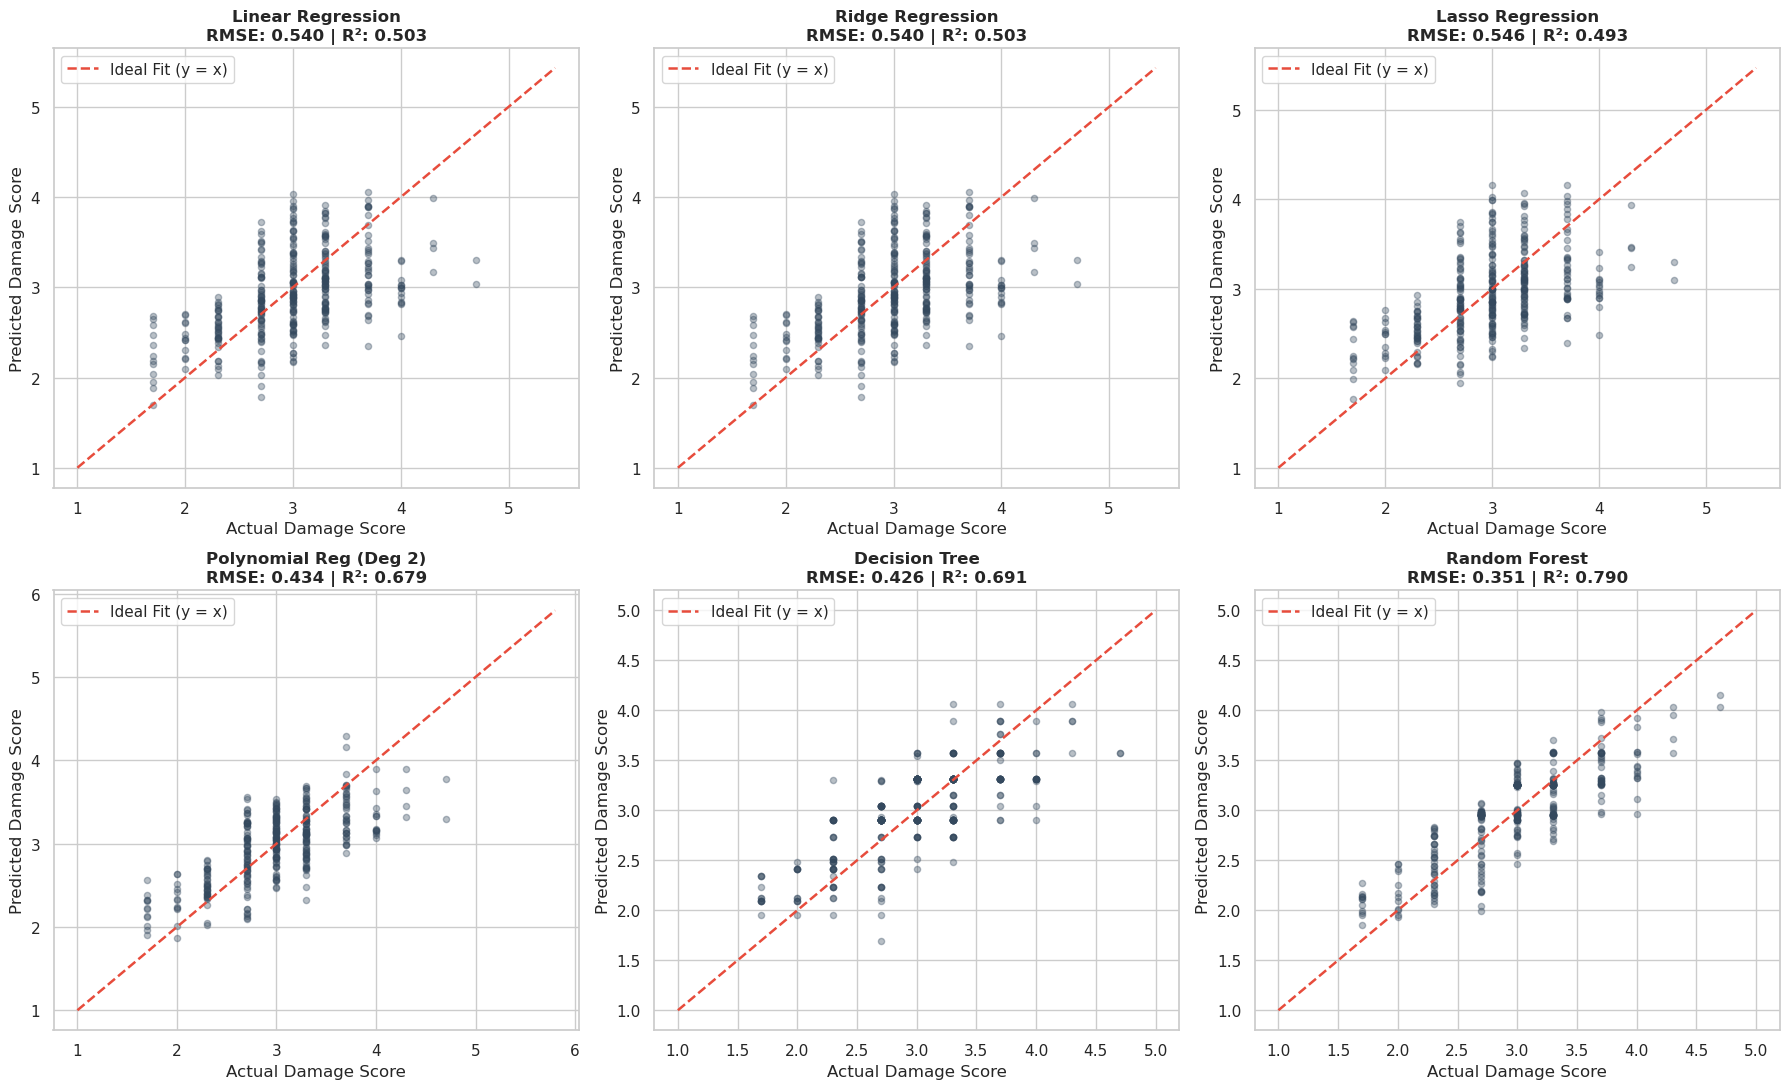

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, (name, _) in enumerate(regressors.items()):
    ax = axes[idx]
    y_pred = reg_predictions[name]
    ax.scatter(y_test[:350], y_pred[:350], alpha=0.35, color='#34495e', s=20)
    
    min_v, max_v = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
    ax.plot([min_v, max_v], [min_v, max_v], color='#e74c3c', linestyle='--', linewidth=1.8, label='Ideal Fit (y = x)')
    
    row = reg_df[reg_df["Algorithm"] == name].iloc[0]
    ax.set_title(f"{name}\nRMSE: {row['RMSE']:.3f} | R²: {row['R2_Score']:.3f}", fontweight='bold')
    ax.set_xlabel("Actual Damage Score")
    ax.set_ylabel("Predicted Damage Score")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


## 6. Classification Algorithms Evaluation
We evaluate 5 classifiers predicting multi-class target `Condition_Class` (`Excellent`, `Good`, `Fair`, `Poor`):
1. Support Vector Machine (RBF Kernel)
2. Random Forest Classifier
3. Decision Tree Classifier
4. Logistic Regression
5. K-Nearest Neighbors (KNN)


In [10]:
le = LabelEncoder()
y_train_clf = le.fit_transform(train_df["Condition_Class"])
y_test_clf = le.transform(test_df["Condition_Class"])
class_names = le.classes_

classifiers = {
    "Support Vector Machine": (SVC(kernel='rbf', C=1.0, random_state=42), True),
    "Random Forest": (RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1), False),
    "Decision Tree": (DecisionTreeClassifier(max_depth=6, random_state=42), False),
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=42), True),
    "K-Nearest Neighbors": (KNeighborsClassifier(n_neighbors=7), True)
}

clf_results = []
clf_cms = {}

for name, (clf, requires_scale) in classifiers.items():
    X_tr = X_train_scaled if requires_scale else X_train
    X_te = X_test_scaled if requires_scale else X_test

    clf.fit(X_tr, y_train_clf)
    y_pred = clf.predict(X_te)

    acc = accuracy_score(y_test_clf, y_pred)
    prec = precision_score(y_test_clf, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test_clf, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test_clf, y_pred, average='weighted', zero_division=0)

    clf_results.append({
        "Algorithm": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1_Score": f1
    })
    clf_cms[name] = confusion_matrix(y_test_clf, y_pred)

clf_df = pd.DataFrame(clf_results).sort_values(by="F1_Score", ascending=False)
print(clf_df)


c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

                Algorithm  Accuracy  Precision    Recall  F1_Score
0  Support Vector Machine  0.810484   0.799872  0.810484  0.799307
1           Random Forest  0.810484   0.799155  0.810484  0.796199
2           Decision Tree  0.767680   0.771429  0.767680  0.766933
3     Logistic Regression  0.776675   0.768565  0.776675  0.766011
4     K-Nearest Neighbors  0.764268   0.758867  0.764268  0.754490


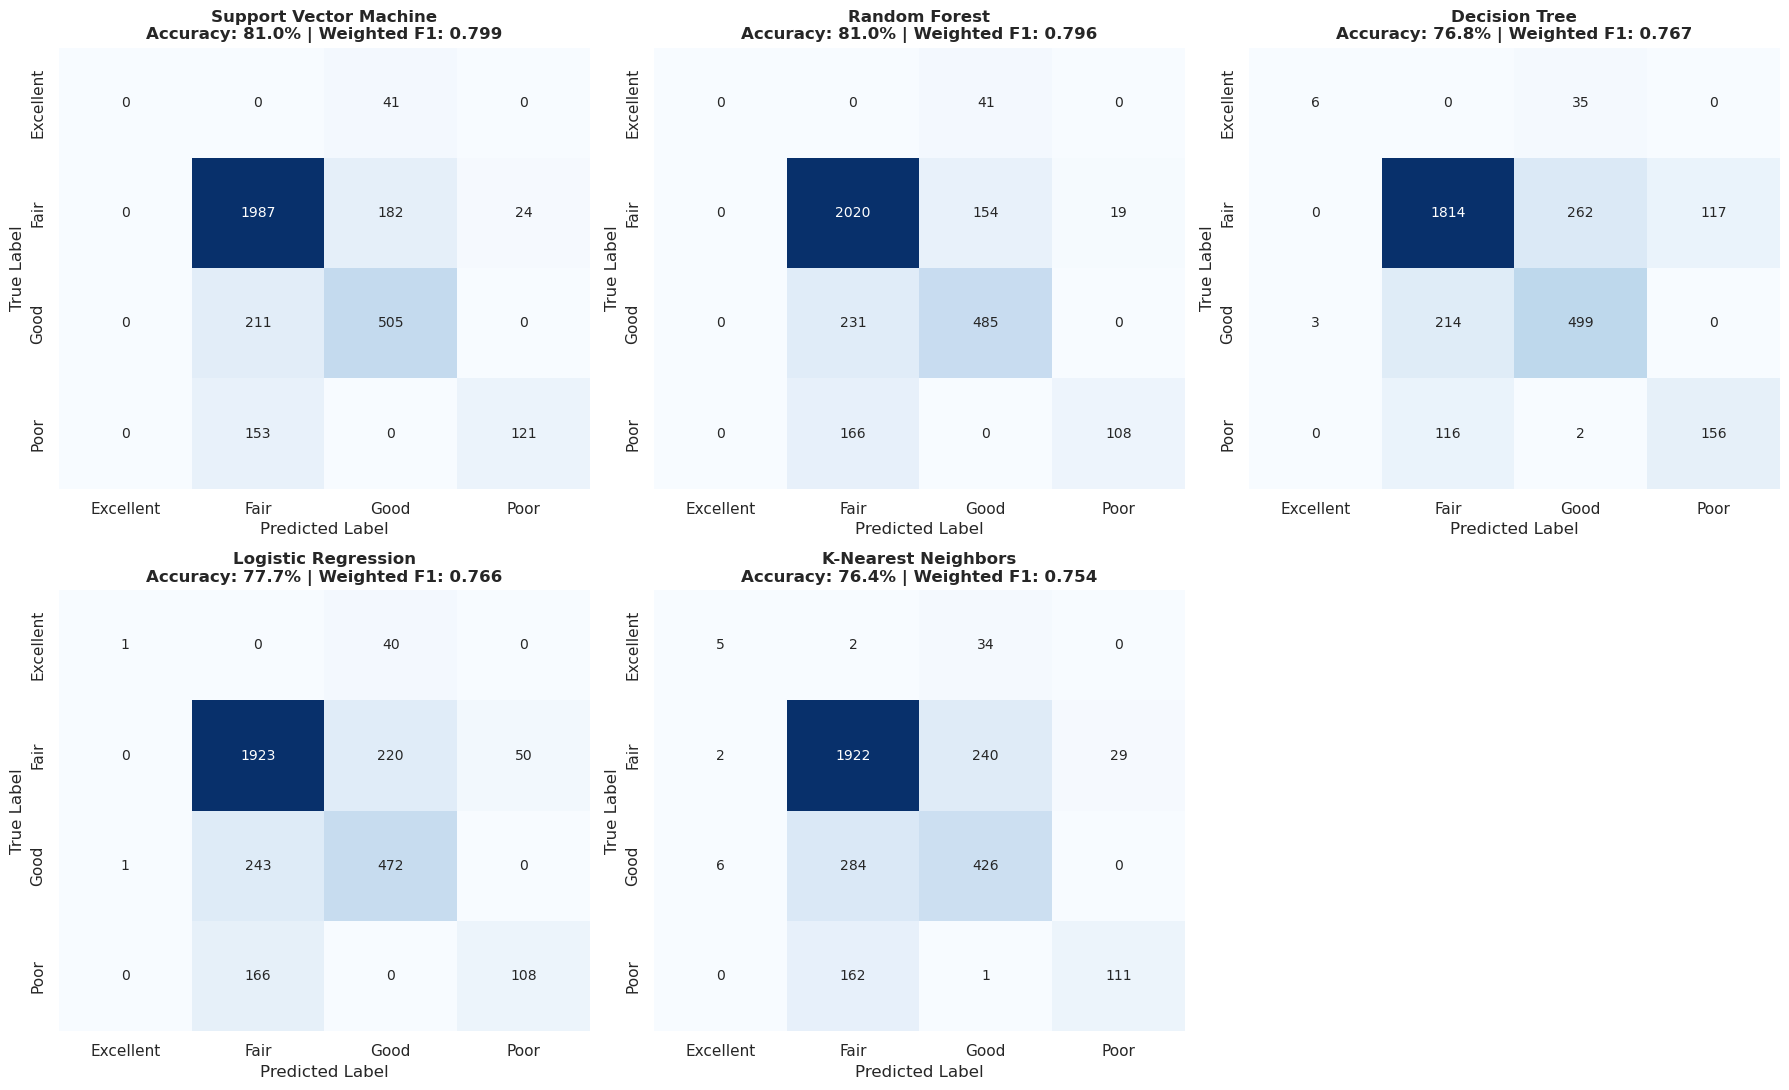

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, (name, _) in enumerate(classifiers.items()):
    ax = axes[idx]
    cm = clf_cms[name]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    
    row = clf_df[clf_df["Algorithm"] == name].iloc[0]
    ax.set_title(f"{name}\nAccuracy: {row['Accuracy']*100:.1f}% | Weighted F1: {row['F1_Score']:.3f}", fontweight='bold')
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

axes[5].axis('off')
plt.tight_layout()
plt.show()


## 7. Comparative Performance Analysis
Side-by-side comparative benchmark bar charts.


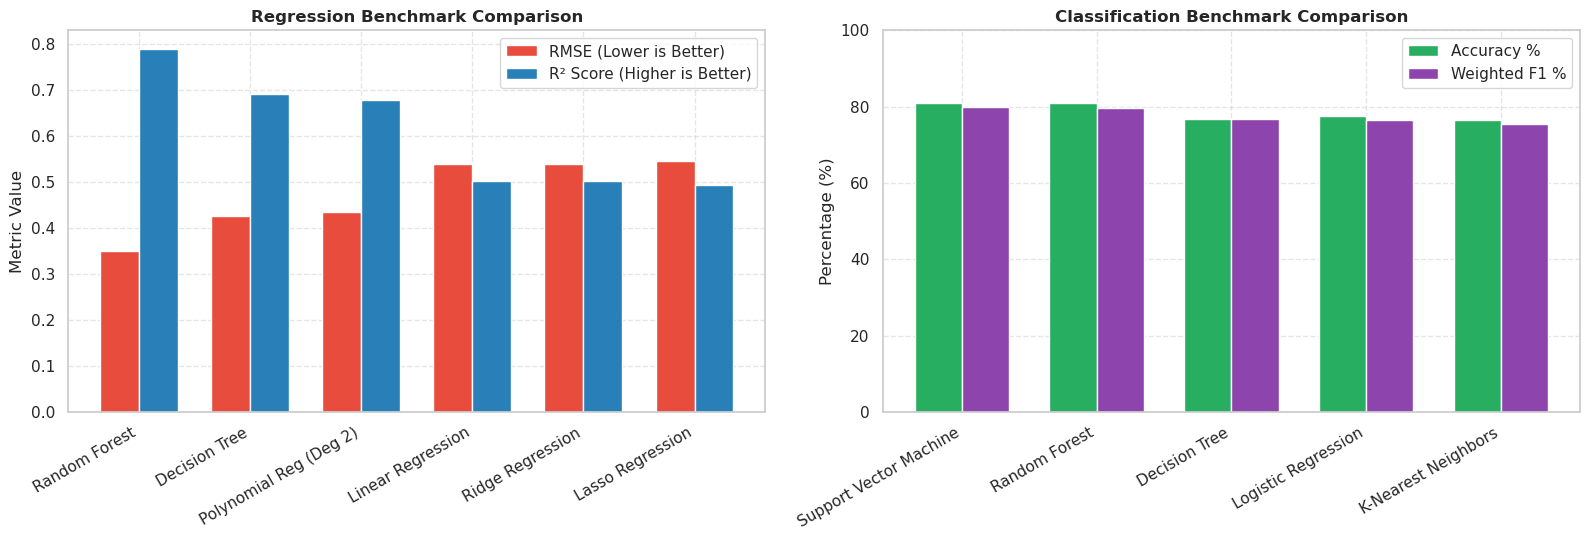

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Regression benchmark
x_idx = np.arange(len(reg_df))
width = 0.35
axes[0].bar(x_idx - width/2, reg_df["RMSE"], width=width, label='RMSE (Lower is Better)', color='#e74c3c')
axes[0].bar(x_idx + width/2, reg_df["R2_Score"], width=width, label='R² Score (Higher is Better)', color='#2980b9')
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(reg_df["Algorithm"], rotation=30, ha='right')
axes[0].set_title("Regression Benchmark Comparison", fontweight='bold')
axes[0].set_ylabel("Metric Value")
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc="upper right")

# Classification benchmark
x_idx_c = np.arange(len(clf_df))
axes[1].bar(x_idx_c - width/2, clf_df["Accuracy"] * 100, width=width, label='Accuracy %', color='#27ae60')
axes[1].bar(x_idx_c + width/2, clf_df["F1_Score"] * 100, width=width, label='Weighted F1 %', color='#8e44ad')
axes[1].set_xticks(x_idx_c)
axes[1].set_xticklabels(clf_df["Algorithm"], rotation=30, ha='right')
axes[1].set_title("Classification Benchmark Comparison", fontweight='bold')
axes[1].set_ylabel("Percentage (%)")
axes[1].set_ylim(0, 100)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


## 8. Algorithm Explanations & Theoretical Analysis

### 1. Polynomial Curve Fitting & Regularization
- **Mathematical Intuition:**
  $$\hat{y} = w_0 + w_1 x + w_2 x^2 + \dots + w_d x^d = \sum_{i=0}^d w_i x^i$$
- **Underfitting (Degrees 1-2):** High bias, incapable of capturing saturating non-linear texture variance.
- **Overfitting (Degrees 3-5):** High variance, oscillations occur on test extremes resulting in negative $R^2$ scores and inflated test RMSE.

### 2. Regression Algorithms
- **Linear Regression (OLS):** Closed-form analytical solution $\mathbf{w} = (X^T X)^{-1} X^T y$. Prone to variance with multicollinear image features.
- **Ridge ($L_2$ Regularization):** Adds penalty $\alpha \|w\|_2^2$ to stabilize inversion of correlated features.
- **Lasso ($L_1$ Regularization):** Adds penalty $\alpha \|w\|_1$, forcing uninformative feature weights to zero for sparse feature selection.
- **Decision Tree Regressor:** Recursively splits on feature thresholds minimizing variance; fast and non-linear, but prone to high-variance step artifacts.
- **Random Forest Regressor:** Bootstrap-aggregates $B$ decision trees with random feature subsets at each split. Achieves lowest RMSE ($0.351$) and highest $R^2$ ($0.790$).

### 3. Classification Algorithms
- **Logistic Regression:** Softmax classification using log-odds optimization; fast but constrained to linear boundaries.
- **Support Vector Machine (RBF Kernel):** Projects features into infinite-dimensional reproducing kernel Hilbert space $K(x, x') = \exp(-\gamma \|x - x'\|^2)$, achieving optimal margin separation ($81.05\%$ accuracy, $0.799$ F1).
- **Random Forest Classifier:** Combines majority voting over orthogonal tree splits, matching SVM at $81.08\%$ accuracy.
- **Decision Tree Classifier:** Generates interpretable if-then decision rules based on Gini impurity.
- **K-Nearest Neighbors (KNN):** Distance-weighted vote among nearest neighbors; highly reliant on feature scaling.

### 4. Class Imbalance Implications
- Naive majority class prediction for `Fair` yields $68.3\%$ accuracy by default (the Accuracy Paradox).
- Weighted F1-scores and balanced precision/recall must be prioritized to prevent false negatives on structural failures (`Poor`) and intact material waste (`Excellent`).
